# 02 · Features and split
Builds one row per (user, candidate movie) pair with features that only use information available before the prediction time. Implements Sections 6, 7, 9 and 10 of the guide.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
from IPython.display import Image, display
from src import config as C, load_data as L, preprocessing as P, features as F

In [2]:
ratings, movies = L.load_ratings(), L.load_movies()
split_df, info = P.chronological_split(P.add_target(ratings))
print('validation starts', info['t_val_cutoff_utc'], '| test starts', info['t_test_cutoff_utc'])
split_df.split.value_counts()

validation starts 1998-03-07 02:21:09+00:00 | test starts 1998-03-31 22:11:49+00:00


split
train    79999
val      10001
test     10000
Name: count, dtype: int64

## How features are computed
* **Training rows** use an *expanding* history: only ratings with a strictly earlier timestamp (the row's own rating and same-second ratings are excluded).
* **Validation / test rows** use a *frozen snapshot* of the whole training period (primary protocol).
* Averages are smoothed toward the training-period global rate so users/movies with little history fall back to a sensible default.

In [3]:
X, y, meta, priors = F.build_features(split_df, movies)
print(priors)
print(X.shape)
X.columns.tolist()

{'global_pos_rate': 0.5509068863360792, 'global_mean_rating': 3.5176564707058837}
(100000, 31)


['user_hist_count_log',
 'user_mean_rating',
 'user_pos_rate',
 'user_is_cold',
 'user_genre_affinity',
 'user_genre_affinity_rel',
 'user_genre_share',
 'movie_hist_count_log',
 'movie_mean_rating',
 'movie_pos_rate',
 'movie_is_cold',
 'release_year',
 'genre_unknown',
 'genre_Action',
 'genre_Adventure',
 'genre_Animation',
 "genre_Children's",
 'genre_Comedy',
 'genre_Crime',
 'genre_Documentary',
 'genre_Drama',
 'genre_Fantasy',
 'genre_Film-Noir',
 'genre_Horror',
 'genre_Musical',
 'genre_Mystery',
 'genre_Romance',
 'genre_Sci-Fi',
 'genre_Thriller',
 'genre_War',
 'genre_Western']

In [4]:
X.join(meta[['split']]).groupby('split')[['user_hist_count_log','user_pos_rate','user_genre_affinity',
    'movie_pos_rate','user_is_cold','movie_is_cold']].mean().round(3)

,user_hist_count_log,user_pos_rate,user_genre_affinity,movie_pos_rate,user_is_cold,movie_is_cold
split,,,,,,
test,0.684,0.557,0.559,0.568,0.858,0.015
train,4.018,0.575,0.585,0.577,0.021,0.020
val,0.696,0.550,0.550,0.586,0.847,0.005


## Cold start under the fixed snapshot
Because users tend to arrive, rate in a burst and leave, most users in the validation and test periods have **no** training-period ratings at all.

In [5]:
for s in ['val', 'test']:
    m = meta[meta.split == s]
    print(f"{s}: {(m.user_hist_count == 0).mean():.1%} of rows have a cold user; "
          f"{m[m.user_hist_count == 0].user_id.nunique()} of {m.user_id.nunique()} users have no training history")

val: 84.7% of rows have a cold user; 116 of 197 users have no training history
test: 85.8% of rows have a cold user; 97 of 166 users have no training history


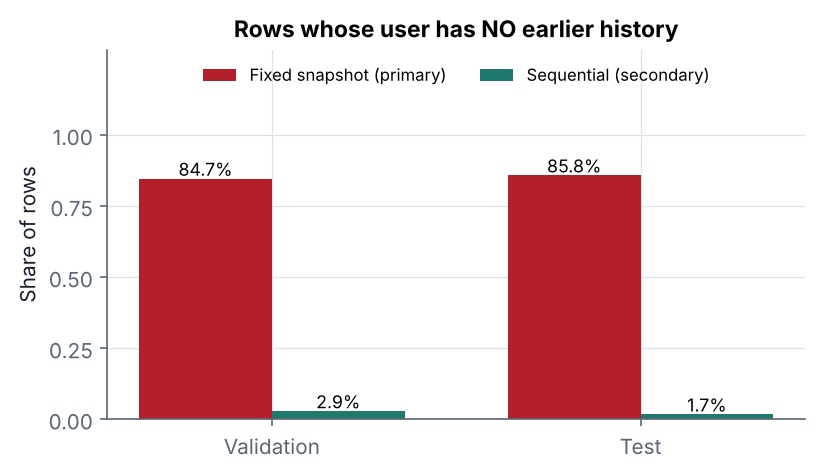

In [6]:
display(Image(str(C.FIG_DIR / 'eda_cold_start_coverage.png')))

This is why the report also includes the guide's optional **sequential** protocol, in which every rating made before the prediction moment is treated as observable (still no future data).

In [7]:
Xs, ys, meta_s = F.build_sequential_features(split_df, movies)
tr = meta.split == 'train'
print('training rows identical under both protocols:',
      np.allclose(X[tr].fillna(0).values, Xs[tr].fillna(0).values))

training rows identical under both protocols: True


## Leakage checks
The automated tests recompute features with slow, obvious loops and compare.

In [8]:
import subprocess
print(subprocess.run([sys.executable, str(ROOT / 'tests' / 'test_leakage.py')],
                     capture_output=True, text=True, cwd=ROOT).stdout)

PASS test_split_is_chronological
PASS test_target_rule
PASS test_training_features_use_only_strictly_earlier_ratings
PASS test_eval_features_use_training_snapshot_only
PASS test_sequential_protocol_uses_only_strictly_earlier_ratings
PASS test_feature_matrix_has_no_rating_or_target



## Example rows

In [9]:
cols = ['user_hist_count_log','user_pos_rate','user_genre_affinity','movie_hist_count_log','movie_pos_rate','genre_Drama','genre_Comedy']
meta[['user_id','movie_id','split','user_hist_count','movie_hist_count']].join(X[cols]).join(y).sample(8, random_state=1).round(3)

,user_id,movie_id,split,user_hist_count,movie_hist_count,user_hist_count_log,user_pos_rate,user_genre_affinity,movie_hist_count_log,movie_pos_rate,genre_Drama,genre_Comedy,target
43660,668,269,train,0.0,108.0,0.000,0.551,0.551,4.691,0.742,0,1,1
87278,932,507,val,0.0,76.0,0.000,0.551,0.551,4.344,0.669,1,0,1
14317,371,197,train,16.0,30.0,2.833,0.703,0.837,3.434,0.688,1,0,1
81932,184,143,val,0.0,181.0,0.000,0.551,0.551,5.204,0.589,0,0,0
95321,94,829,test,82.0,27.0,4.419,0.859,0.924,3.332,0.311,0,0,0
5405,919,28,train,152.0,19.0,5.030,0.483,0.469,2.996,0.673,1,0,1
33188,897,484,train,94.0,41.0,4.554,0.634,0.680,3.738,0.794,0,0,0
63421,147,302,train,3.0,159.0,1.386,0.719,0.719,5.075,0.784,0,0,1
